<a href="https://colab.research.google.com/github/rgaratac/dust_tool_test/blob/feature/simplified-tool/Dust_deduction_tool_simple.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Natural Dust service Tool

This notebook presents the **CAMS Natural Dust Service Tool**, which supports EU Member States in identifying and quantifying the contribution of natural dust to measured $PM_{10}$ and $PM_{2.5}$ concentrations, as required under Article 16 of the revised Ambient Air Quality Directive (Directive (EU) 2024/2881). The tool estimates the natural dust contribution and subtracts it from the measured concentrations, yielding dust-corrected surface $PM_{10}$ and $PM_{2.5}$ values.

> AAQD (2024/2881) Article 16: Member states are requested to identify a) zones where exceedances of limit values for a given pollutant are attributable to natural sources and b) average exposure territorial units, where exceedances of the level determined by the average exposure reduction obligations are attributable to natural sources.

The Natural Dust Service Tool implements the EU methodology for natural contributions. Stations are classified as regional background (RB), urban/suburban background (UB) or traffic/industrial hotspots (TH) and paired with a nearby RB (and, for TH, a UB) station. The natural load is quantified at the reference station (Option 1) or by self-calibration of UB stations (Option 2) and subtracted on every natural-event day. The CAMS interim reanalysis dust product is used to identify days affected by natural dust.


# Outline
- [ 1 - Import Packages ](#1)
- [ 2 - Country selection and Threshold settings](#2)
- [ 3 - Download data ](#3)
- [ 4 - Data preparation ](#4)
  - [ 4.6 - Station classification and pairing ](#4.6)
- [ 5 - Flag dust days with CAMS data](#5)
- [ 6 - Calculate the dust contribution](#6)
- [ 7 - Save or load results](#7)
- [ 8 - Visualization](#8)
  - [ 8.4 - Exceedance report ](#8.4)

This is the simplified version of the tool: the cells only hold the options, the code is in `dust_tool.py` (processing steps) and `dust_plots.py` (plots).

Created by Jessie Zhang, TNO
          22/05/2026

<a name="1"></a>
## **1 - Import Packages**

Run the cell below to load the required packages and the helper functions. If everything loads correctly, the last line of the output reads:

> util.py has been imported




In [ ]:
!pip install -q cartopy
from importlib.metadata import version as _pkg_version
# Plotly 6 widgets bundle their own JS, so the maps also render in VS Code.
if int(_pkg_version('plotly').split('.')[0]) < 6:
    %pip install -q "plotly>=6" anywidget
import importlib, importlib.util, urllib.request, requests
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import display
try:
    IN_COLAB = importlib.util.find_spec('google.colab') is not None
except ModuleNotFoundError:  # no 'google' package at all (local Python)
    IN_COLAB = False

GITHUB_BRANCH = 'feature/simplified-tool'   # branch of rgaratac/dust_tool_test the modules are downloaded from (Colab)
MODULES = ['util', 'cams_data_to_eea_daily', 'pairing', 'natural_contribution', 'pairing_viz',
           'dust_threshold_sensitivity', 'exceedance_report', 'dust_tool', 'dust_plots']
try:
    # Pin to the latest commit: raw.githubusercontent.com caches a branch for several minutes.
    _sha = requests.get(f'https://api.github.com/repos/rgaratac/dust_tool_test/commits/{GITHUB_BRANCH}',
                        headers={'Accept': 'application/vnd.github.sha'}, timeout=10).text.strip()
except Exception:
    _sha = ''
raw_base = f"https://raw.githubusercontent.com/rgaratac/dust_tool_test/{_sha if len(_sha) == 40 else GITHUB_BRANCH}"
for name in MODULES:
    # Locally the repo copies are kept, so local edits are not overwritten.
    if IN_COLAB or not Path(f'{name}.py').exists():
        urllib.request.urlretrieve(f'{raw_base}/{name}.py', f'{name}.py')
# Re-running this cell picks up edited modules without restarting the kernel.
for name in MODULES:
    importlib.reload(importlib.import_module(name))
import dust_tool as dt
import dust_plots as dp
import pairing_viz as pv
print('dust_tool and dust_plots have been imported')


<details>
<summary><font size="2" color="darkgreen"><b>Troubleshooting</b></font></summary>
Remove <font size="2" color="blue"> <b>%%capture</b></font> and output should show in the end:

> dust_tool and dust_plots have been imported

If functions are modified in util.py please reload the file use the code below
```
import sys, importlib, os, inspect
import util
importlib.invalidate_caches()
if 'util' in sys.modules:
    del sys.modules['util']
import util
importlib.reload(util)  # extra safety

# Double-check the function exists and from which file it's loaded
print("Has function?", hasattr(util, 'plot_station_timeseries'))
if hasattr(util, 'plot_station_timeseries'):
    print(inspect.getsource(util.plot_station_timeseries)[:400])  # peek at the first lines

```
If one of the modules are not loading  try

```
!pip install <package-name>
```
The interactive map widgets are designed for Google Colab and may not work in VS Code or on an HPC system. In that case, use the static plots in Section 7, entering the column names you want to plot.




<a name="2"></a>
## **2- Country selection and Threshold settings**
Select one or more countries from the table below by listing their codes in `countries`, then choose the year (`year`), pollutant (`pollutant`), dataset (`dataset`) and time resolution (`temporal_flag`, `hour` or `day`). `compute_cams_daily` builds the CAMS daily mean that matches that choice: UTC days for hourly EEA data, and each station's local day for daily EEA data.
The data only need to be downloaded and processed once. After that, the tool reuses the stored files:

<center>

| Flag | First run | Later runs | What it does |
|---|---|---|---|
| `download_eea` | `True` | `False` | Downloads the EEA observations and stores them as a zip file |
| `download_cams` | `True` | `False` | Downloads the CAMS interim reanalysis dust data |
| `compute_cams_daily` | `True` | `False` | Builds the daily CAMS product from the hourly zips. `hour` writes a UTC daily grid; `day` writes per-station local-day means. Turned on automatically when `download_cams` is True |
| `load_parquet` | `False` | `True` | Loads the saved Parquet file with the processed results instead of recomputing them |


### Available countries in EEA

| Country Code | Country Name           | Country Code | Country Name           |
|-------------|-------------------------|-------------|-------------------------|
| AD          | Andorra                | IT          | Italy                  |
| AL          | Albania                | LT          | Lithuania              |
| AT          | Austria                | LU          | Luxembourg             |
| BA          | Bosnia and Herzegovina | LV          | Latvia                 |
| BE          | Belgium                | ME          | Montenegro             |
| BG          | Bulgaria               | MK          | North Macedonia        |
| CH          | Switzerland            | MT          | Malta                  |
| CY          | Cyprus                 | NL          | Netherlands            |
| CZ          | Czechia                | NO          | Norway                 |
| DE          | Germany                | PL          | Poland                 |
| DK          | Denmark                | PT          | Portugal               |
| EE          | Estonia                | RO          | Romania                |
| ES          | Spain                  | RS          | Serbia                 |
| FI          | Finland                | SE          | Sweden                 |
| FR          | France                 | SI          | Slovenia               |
| GB          | United Kingdom         | SK          | Slovakia               |
| GR          | Greece                 | XK          | Kosovo                |  
| HR          | Croatia                |             |                         |
| HU          | Hungary                |             |                         |
| IE          | Ireland                |             |                         |
| IS          | Iceland                |             |                         |

</center>

Available EEA datasets:


1.   Verified data (`E1a`): Validated measurements available from 2013, reported annually by countries for the previous year.

2.   Up-to-date data (`E2a`): Unverified measurements transmitted continuously, available from 2023.

E2a daily aggregation deoes not have any station data for 2025.



In [ ]:
settings = dt.Settings(
    year               = 2025,      # target year
    temporal_flag      = 'day',     # 'hour' (EEA hourly data, UTC daily CAMS) or 'day' (EEA daily data, local-day CAMS)
    dataset            = 'E1a',     # 'E1a' or 'E2a'
    pollutant          = 'PM2.5',   # 'PM10' or 'PM2.5'
    countries          = ['ES'],    # e.g. ['ES', 'PT']; all countries: dt.ALL_COUNTRIES
    download_eea       = False,
    download_cams      = False,
    compute_cams_daily = False,
    load_parquet       = True,      # True: load the saved results instead of recomputing them
    project_dir        = '.',
    use_google_drive   = None,      # None: Google Drive in Colab, project_dir locally
)

**Thresholds, limit values and method parameters**

The parameters can be adjusted below, for example to reflect future changes in the guidelines or limit values:

*   `cams_dust_threshold`: CAMS dust concentration (µg/m³) above which a day is flagged as a natural-event (dust) day.
*   `pm10_daily_limit`, `pm25_daily_limit`, `pm10_annual_limit`, `pm25_annual_limit`: limit values (µg/m³). The daily PM10 default is 45 µg/m³ (Directive (EU) 2024/2881); set 50 to use the previous limit. `tool.daily_limit` and `tool.annual_limit` follow `pollutant`.
*   `station_coverage`: minimum annual data coverage (%) required for an EEA station to be included.

Station pairing (section 4.6):

*   `pairing_mode`: `'default'` pairs each station with an RB (or UB) reference as described in section 4.6. `'none'` does not pair: every station is its own reference. RB stations use Option 1 on their own data (±`option1_half_window` days, about 30 days) and all other stations use Option 2 self-calibration (±`option2_half_window` days around the episode, 6 days). With `'none'` the limits below and `use_user_pairing` are ignored.
*   `max_rb_distance_km`, `max_rb_altitude_diff_m`: a regional background (RB) station is a suitable reference only within this horizontal distance and altitude difference.
*   `max_ub_distance_km`: maximum distance between a traffic/industrial (TH) station and its urban background (UB) reference.
*   `pair_same_country`: only pair stations of the same country.
*   `use_user_pairing`: when True and `station_pairing_user.csv` exists in the output folder, it replaces the default pairing.
*   `reapply_pairing_on_load`: when results are loaded from Parquet, recompute the deduction with the current pairing (the first and last 15 days of the year then have a shorter Option 1 window).

Methods (section 6):

*   `option1_half_window` (15) and `option2_half_window` (3): days before and after an event day (or an episode for Option 2) in the reference window. Event days are always excluded.
*   `reference_percentile` (50): percentile of the reference window.
*   `min_reference_days_option1`, `min_reference_days_option2`: minimum valid reference days; otherwise the day is flagged `insufficient_reference` and nothing is subtracted.


In [ ]:
settings.cams_dust_threshold        = 5         # µg/m3 total dust

# Limit values, µg/m3 (Directive (EU) 2024/2881). Use 50 for the previous daily PM10 limit.
settings.pm10_daily_limit           = 45
settings.pm25_daily_limit           = 25
settings.pm10_annual_limit          = 20
settings.pm25_annual_limit          = 10

settings.station_coverage           = 65        # % of the days of the year with data

# Station pairing
settings.pairing_mode               = 'default' # 'default': pair with RB/UB references; 'none': no pairing
settings.max_rb_distance_km         = 100
settings.max_rb_altitude_diff_m     = 500
settings.max_ub_distance_km         = 50
settings.pair_same_country          = True
settings.use_user_pairing           = False     # True: use station_pairing_user.csv from the output folder
settings.reapply_pairing_on_load    = True

# Natural-contribution methods
settings.option1_half_window        = 15
settings.option2_half_window        = 3
settings.reference_percentile       = 50
settings.min_reference_days_option1 = 10
settings.min_reference_days_option2 = 3

tool = dt.DustTool(settings)

<a name="3"></a>
## **3- Download data**

This section downloads the two datasets the tool needs:


*   **EEA observations** of the selected pollutant, from the EEA air quality download service
*   **CAMS interim reanalysis dust**, from the Copernicus Atmosphere Data Store (ADS)

Both downloads only need to run once. The files are stored in your output folder (CAMS_Tool_output on Google Drive, or the project folder when use_google_drive = False) and reused in later runs.


**3.1 EEA observations**

When `download_eea` = True, the cell below requests the EEA data for the selected countries, pollutant, dataset, year and time resolution. The download covers 14 December of the previous year to 31 December of the selected year, so that the background concentration can also be calculated for the first days of the year.

The EEA service prepares the file on request. Large requests (many countries or hourly data) can take several minutes. Daily requests use the same API, dataset ids (`E2a` = 1, `E1a` = 2), countries, pollutant and year span, with `aggregationType` set to `day`.

The data are saved as a zip file named {dataset}_{POLLUTANT}_{temporal_flag}_{YEAR}.zip and extracted to EEA_{POLLUTANT}/{YEAR}/{dataset}/{temporal_flag}. If a zip file for the same selection already exists, it is replaced by the new download. When download_eea = False, the cell extracts the zip file saved in a previous run.

In [ ]:
tool.download_eea()

**3.1.1 Optional: use your own observations instead of the EEA download**

Set `USE_USER_OBSERVATIONS = True` in the next cell to use your own measurements. Leave `download_eea = False`. The rest of the notebook (CAMS matching, pairing, deduction, plots) is the same. Output files use `USER_DATASET_LABEL` (default `user`) instead of `dataset`, so they do not overwrite the EEA results.

Two CSV files are needed, both in the same layout as the EEA data: the observations in the layout of the EEA observation files, and the stations in the layout of `DataExtract.csv`. **All columns below are required and every cell must be filled in** (only `Value` may be empty for a missing measurement), except the optional `Validity` and `Verification` columns. Extra columns, such as the other `DataExtract.csv` columns, are ignored. Comma- or semicolon-separated.

Put the files in the output folder (CAMS_Tool_output on Google Drive, or the project folder), or set `UPLOAD_USER_FILES = True` in Colab to choose them on your computer. If a file is missing, the cell writes `user_observations_example.csv` and `user_stations_example.csv` in the right format, which you can fill in and rename. The files are checked when they are read; a wrong value stops the cell with the row and column to fix.

**Observations file** (`user_observations.csv`, EEA observation layout): one row per station and day (`temporal_flag = 'day'`) or per station and hour (`'hour'`).

| Column | Description |
|---|---|
| `Samplingpoint` | `<country code>/<Sampling Point Id>`, e.g. `ES/SP_28079004_10_6`. Must be in the stations file |
| `Pollutant` | `PM10` or `PM2.5` (or the EEA codes `5` and `6001`). Rows of another pollutant than `pollutant` are skipped |
| `Start`, `End` | Start and end of the period, `YYYY-MM-DD HH:MM:SS`. Daily: local time of the station. Hourly: fixed UTC+1 like the EEA hourly data, unless an offset is given (`2025-01-01 13:00:00+00:00`) |
| `Value` | Concentration in µg/m³. Empty or negative values are skipped |
| `Unit` | `ug.m-3` |
| `AggType` | `day` or `hour`. Rows that do not match `temporal_flag` are skipped |
| `Validity` *(optional)* | EEA validity flag. If the column is present, only `1` (valid) is used |
| `Verification` *(optional)* | EEA verification flag: `1` verified, `2` preliminary verified, `3` not verified. If the column is present, only `1` and `2` are used |

Without `Validity` and `Verification`, every row with a value of 0 or more is used, so remove invalid measurements from the file first.

```
Samplingpoint,Pollutant,Start,End,Value,Unit,AggType
ES/SP_MY_STATION_1,PM10,2025-01-01 00:00:00,2025-01-02 00:00:00,21.4,ug.m-3,day
ES/SP_MY_STATION_1,PM10,2025-01-02 00:00:00,2025-01-03 00:00:00,35.0,ug.m-3,day
ES/SP_MY_STATION_2,PM10,2025-01-01 00:00:00,2025-01-02 00:00:00,40.1,ug.m-3,day
```

Hourly data: only days with 24 hourly values are kept, as for the EEA data. Include data from 14 December of the previous year so the reference window also covers the first days of `year`. Stations need at least `station_coverage` % of the days of `year`.

**Stations file** (`user_stations.csv`, `DataExtract.csv` layout): one row per sampling point and pollutant. A station in this file replaces the `DataExtract.csv` entry with the same id.

| Column | Description |
|---|---|
| `Air Quality Station EoI Code` | Station code starting with the country code, e.g. `ES9001A`. The country code must be in `countries` |
| `Air Quality Station Name` | Station name, shown on the maps |
| `Sampling Point Id` | Id after the `/` in `Samplingpoint` |
| `Air Pollutant` | `PM10` or `PM2.5` |
| `Longitude`, `Latitude` | Decimal degrees |
| `Altitude` | m above sea level, used for the RB altitude limit |
| `Air Quality Station Area` | `urban`, `suburban`, `rural`, `rural-nearcity`, `rural-regional` or `rural-remote` |
| `Air Quality Station Type` | `background`, `traffic` or `industrial` |
| `Timezone` | `UTC`, `UTC+01`, `UTC+02`, `UTC-04`, ...: defines the local day of daily data |

Area and type give the class used for the pairing: rural* + background = RB, urban/suburban + background = UB, traffic or industrial = TH.

```
Air Quality Station EoI Code,Air Quality Station Name,Sampling Point Id,Air Pollutant,Longitude,Latitude,Altitude,Air Quality Station Area,Air Quality Station Type,Timezone
ES9001A,My rural station,SP_MY_STATION_1,PM10,-3.70,40.70,700,rural-regional,background,UTC+01
ES9002A,My traffic station,SP_MY_STATION_2,PM10,-3.69,40.42,650,urban,traffic,UTC+01
```


In [ ]:
tool.load_user_observations(
    enabled           = False,                    # True: use your own observations instead of the EEA download
    observations_file = 'user_observations.csv',  # EEA observation layout, in the output folder
    stations_file     = 'user_stations.csv',      # DataExtract.csv layout, in the output folder
    upload            = False,                    # Colab: choose the files on your computer
    label             = 'user',                   # replaces the dataset name in the output file names
)

**3.2 CAMS dust data**

**3.2.1. Set up your ADS API key**

Downloading CAMS data requires a free account on the Copernicus Atmosphere Data Store (ADS). Before the first download:



1.   Log in to the ADS and copy your API key from your profile page. See the API setup guide for details (https://cds.climate.copernicus.eu/how-to-api).
2.   Accept the licence of the CAMS European air quality reanalyses dataset on its download page. Requests fail until the licence has been accepted.
3. Run the cell below and paste your API key when prompted. The key is saved in ~/.cdsapirc and is not requested again.

To replace an existing key, delete ~/.cdsapirc and run the cell again. If error appeared please try !pip install --user "cdsapi>=0.7.7"
.
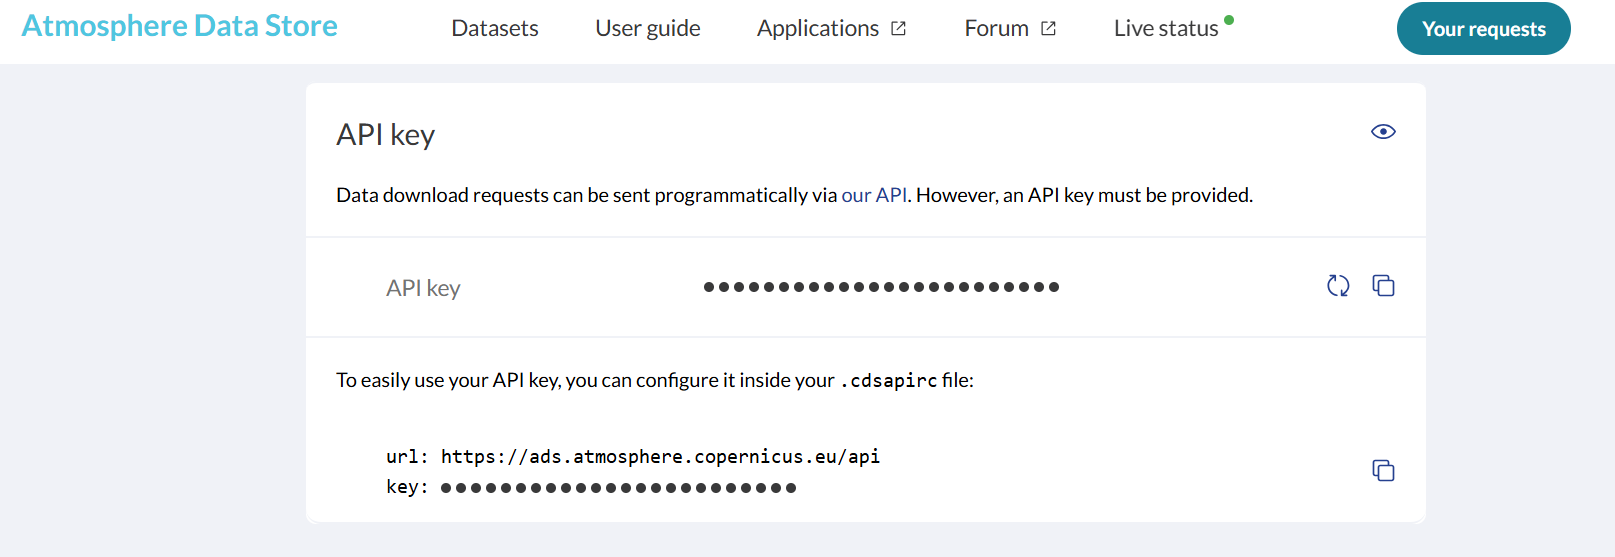

In [ ]:
if settings.download_cams:
    if importlib.util.find_spec('cdsapi') is None:
        %pip install -q "cdsapi>=0.7.7"
    dt.setup_cds_key()

**3.2.2. Download the CAMS dust data**

CAMS zip files are stored in the output folder (`IRA_dust/` on Google Drive when `use_google_drive` is True, otherwise in the project folder). Hourly NetCDF is extracted from those zips onto local disk only when `compute_cams_daily` is True, and the NetCDF is not copied to Drive.

`download_cams = True` sets `compute_cams_daily = True`. An existing zip is reused; only a missing zip is downloaded. The daily mean itself depends on `temporal_flag`: a UTC grid for hourly EEA data, and a local-day mean at each station for daily EEA data.

When `compute_cams_daily` is False, this cell does not extract the zips. Later cells load the daily CAMS file saved by a previous run.


In [ ]:
tool.download_cams()

<a name="4"></a>
## **4- Data preparation**

In this step, the EEA observations and station metadata are loaded and filtered for validity and verification status.



### **4.1 Filter for validity and verification**

Only measurements with validity = 1 (valid) and verification = 1 or 2 (verified or preliminary verified) are kept. Negative values are also removed. The EEA definitions are:

<center>

#### Validity

|ID     | Label                                       | Status    | Status Modified | Notation |
|-------|---------------------------------------------|-----------|-----------------|----------|
| -99   | Not valid due to station maintenance or calibration       | Valid           | 22.03.2013 | -99 |
| -1    | Not valid                                                 | Valid           | 22.03.2013 | -1  |
| 1     | Valid                                                     | Valid           | 22.03.2013 | 1   |
| 2     | Valid, but below detection limit measurement value given  | Valid           | 22.03.2013 | 2   |
| 3     | Valid, but below detection limit and number replaced by 0.5*detection limit | Valid           | 22.03.2013 | 3   |
| 4     | Valid (Ozone only) using CCQM.O3.2019                     | Valid           | 04.07.2024 | 4   |


#### Verification
| Id | Label                  | Status | Status Modified | Notation |
|----|------------------------|--------|-----------------|----------|
| 1  | Verified              | Valid  | 22.03.2013      | 1        |
| 2  | Preliminary verified  | Valid  | 22.03.2013      | 2        |
| 3  | Not verified          | Valid  | 22.03.2013      | 3        |
 <br>


</center>

### **4.2 Filter temporal range**
Only stations with data for the selected year are kept. The pre-downloaded dataset also covers some days before and after the selected year, so that moving averages can be calculated at the start and end of the year. EEA hourly data are provided in CET (UTC+1) and are converted to UTC before being aggregated to daily means.

EEA hourly data are provided in CET (fixed UTC+1, no daylight-saving shift) and `eea_to_utc` converts them to UTC before the daily mean. EEA daily data are different: `Start` is the station's local time, taken from the `Timezone` label in `DataExtract.csv` (`UTC`, `UTC+01`, `UTC-04`, and so on). Those stamps are not passed through `eea_to_utc`. When `temporal_flag` is `day` and `compute_cams_daily` is True, section 4.5 averages CAMS (UTC) over the matching local day: local day D is the UTC window `[D 00:00 - offset, D+1 00:00 - offset)`.


### **4.3 Load and merge station metadata**

The EEA observations identify each station only by its sampling point ID. The station metadata add the latitude, longitude, altitude and time zone of each station, which are needed to match the stations with the CAMS dust data.

Before running this step, download the metadata file manually:




1.   Open the EEA Air Quality Viewer and download the station metadata as a CSV file (https://discomap.eea.europa.eu/App/AQViewer/index.html?fqn=Airquality_Dissem.b2g.measurements).
2.   Name the file DataExtract.csv.
3.   Save it in your output folder (CAMS_Tool_output on Google Drive, or the project folder when use_google_drive = False).

In [ ]:
tool.prepare_observations()

### **4.4 Compute daily mean CAMS dust**

The cell below converts the hourly CAMS dust data downloaded in Section 3 into daily mean dust concentrations over the whole CAMS domain.


*   When `compute_cams_daily` = True: the monthly NetCDF files for the selected year are combined into one hourly dataset and averaged to daily means. Days are defined in UTC, matching the daily means computed from the EEA observations in 4.1. The result is saved as cams_dust_{YEAR}_daily_mean.nc in the IRA_dust folder.
*   When `compute_cams_daily` = False: the daily mean file saved in a previous run is loaded instead.


**Memory note:** Computing the daily means for the full CAMS domain may exceed the memory available on Google Colab. If so, run this step once on a local machine or an HPC system and copy the saved daily mean file to your output folder.

With `temporal_flag = 'day'` this full-domain UTC grid is skipped. Local-day means are built in section 4.5, one UTC day at a time and only at station coordinates, then cached as Parquet under `IRA_dust/` on Google Drive (or in the project folder). A later run reuses those files when they are already there.


### **4.5 Match CAMS dust to each station**

Daily CAMS dust concentrations are interpolated to each station location. The result is a single table with one row per station and day, combining the measured daily mean, the exceedance flag and the CAMS dust concentration.

On the hourly path the UTC daily grid is interpolated with `add_cams_daily_dust_by_station`. On the daily path (`temporal_flag = 'day'`) the notebook calls `add_cams_local_daily_dust` in `cams_data_to_eea_daily.py`. That joins on the local calendar date, not on the nearest UTC day. `compute_cams_daily` decides whether that product is rebuilt; the EEA time resolution decides which average is built. The dust flag, background median, corrected concentration, station summary and plots below are unchanged.


In [ ]:
tool.match_cams()

<a name="4.6"></a>
### **4.6 Station classification and pairing**

Stations are classified from the `Air Quality Station Type` and `Air Quality Station Area` columns of `DataExtract.csv`:

| Class | Rule |
|---|---|
| **RB** regional background | rural* area and background type |
| **UB** urban background | urban or suburban area and background type |
| **TH** hotspot | traffic or industrial type |

#### **4.6.1 Default pairing**

Each non-RB station is paired with the nearest RB station of the same country (`pair_same_country`) within `max_rb_distance_km` and `max_rb_altitude_diff_m`. Each station has at most one reference. A TH station without a suitable RB is paired with the nearest UB station within `max_ub_distance_km`; without RB or UB it gets no reference. An RB station is its own reference. The method follows from the pairing:

| Method | When | Natural load used |
|---|---|---|
| `option1` | suitable RB | net load at the paired RB |
| `option2` | UB without suitable RB | self-calibration at the station |
| `option2_ub_paired` | TH without suitable RB | Option 2 load of the paired UB |
| `none` | no valid reference | nothing is subtracted |

The default pairing is saved as `station_pairing_default.csv`. With `use_user_pairing = True` the edited `station_pairing_user.csv` is applied on top of it. The deduction in section 6 always reads the current pairing table, so edits made below are used the next time section 6 runs.

With `pairing_mode = 'none'` no pairing is done: RB stations use `option1` on their own data (±15-day window) and all other stations (UB, TH and unknown) use `option2` self-calibration (±3-day episode window). Nothing is written to the pairing CSV files.


In [ ]:
tool.build_pairing()

#### **4.6.2 Pairing map and editor**

The interactive map shows every station coloured by class (green RB, blue UB, red TH). Green lines join a station to its RB reference, thinner orange lines join a TH station to its UB reference. Grey markers have method `none`: no natural contribution can be computed (e.g. a TH station without a suitable RB or UB, or an unknown class). A UB station without RB is not grey: it uses Option 2 self-calibration. Hover a station to see its id, name, class, area, altitude, paired stations, distance, altitude difference, method and whether the pairing is default or manual. Use the country and class filters to reduce the map.

To change a pairing, click a station (or type its id or name), choose the paired RB and/or UB from the candidates (sorted by distance, with distance and altitude difference), or choose *none / force Option 2*. **Save** marks the station as manual, recomputes the distances and the method, writes `station_pairing_user.csv` to the output folder and redraws the map. **Reset station** and **Reset all** return to the default pairing.

If the widgets do not work in your environment, use the static map in the next cell and the CSV route in 4.6.3.

With `CLICKABLE_PAIRING_MAP = True` (default) the map is clickable; it needs Plotly 6 or newer, which the first cell installs (restart the kernel if Plotly 5 was already imported). Set it to `False` to draw the map as a static image that is redrawn after each change.

In [ ]:
CLICKABLE_PAIRING_MAP = True   # False: static image fallback
display(tool.pairing_app(clickable_map=CLICKABLE_PAIRING_MAP))

In [ ]:
pairing_countries = settings.countries   # e.g. ['ES']
pairing_classes   = ['RB', 'UB', 'TH']
fig, ax = pv.plot_station_pairing_static(tool.pairing_session.table, pairing_countries, pairing_classes)
plt.show()

#### **4.6.3 Edit the pairing as CSV**

1. Run the first cell below. It writes the current pairing to `station_pairing_user.csv` in the output folder and, in Colab, downloads it.
2. Open the file (e.g. in Excel) and change only `paired_rb_id`, `paired_ub_id`, `method` (`option1`, `option2`, `option2_ub_paired`, `none`, or empty to derive it from the pairing) or `comment`. Other columns are recomputed.
3. Upload it with the second cell (`UPLOAD_PAIRING_CSV = True` in Colab) or save it back as `station_pairing_user.csv` in the output folder, then run the second cell.

On loading, every id must exist, a paired RB must be an RB station and a paired UB a UB station; otherwise the file is rejected with a list of errors. Pairs beyond the distance or altitude limits only give a warning. Changed stations are marked `source = manual` and the changes against the default pairing are listed. The map above is redrawn. Set `use_user_pairing = True` to start from this file in later sessions.

In [ ]:
tool.export_pairing_csv()

In [ ]:
UPLOAD_PAIRING_CSV = False   # Colab: choose the edited CSV on your computer; otherwise place it in the output folder
tool.load_pairing_csv(upload=UPLOAD_PAIRING_CSV)

<a name="5"></a>
## **5- Flag dust days with CAMS data**

Two flags are assigned to every station and day:

*   Dust day (`dust_flag`, stored as `cams_dust_flag` in section 6): the CAMS dust concentration at the station is above `cams_dust_threshold` (default 5 µg/m³). These are the natural-event days.
*   Exceedance (`Exceedance`): the measured daily mean is above the daily limit value, `tool.daily_limit` (default: 45 µg/m³ for $PM_{10}$ or 25 µg/m³ for $PM_{2.5}$).

The natural contribution is quantified and subtracted on **every** dust day in Section 6, whether or not there is an exceedance.

In [ ]:
tool.flag_dust_days()

<a name="6"></a>
## **6 - Calculate the dust contribution**

The natural contribution is quantified with the method set in the pairing table (section 4.6). Event days (CAMS dust days) are excluded from every reference window.

**Option 1 – regional background (preferred).** At the paired RB station, for each event day *d*, the reference is the `reference_percentile` (50th) percentile of the days *d*−15 … *d*+15 that are not event days. The net natural load at the RB is max(measured RB(*d*) − reference, 0). The same daily load is subtracted at every station paired to that RB, including the RB itself.

**Option 2 – self-calibration (UB without suitable RB).** At the station itself, window *d*−3 … *d*+3 without event days. For a multi-day episode, the 3 days before its start and the 3 days after its end (without event days) are the reference for every day of the episode.

**TH stations** do not self-calibrate: they use the Option 1 load of their RB or, without a suitable RB, the Option 2 load of their paired UB.

If fewer than `min_reference_days_option1` / `min_reference_days_option2` valid reference days are available, the day is flagged `insufficient_reference` and nothing is subtracted.

The contribution is subtracted on every event day, with or without an exceedance; other days get 0. Adjusted value = measured − contribution (never below 0). A dust day is confirmed only when the quantified contribution is > 0.

The calculation uses the whole downloaded period (from 14 December of the previous year) and then keeps the selected year.

In [ ]:
tool.run_deduction()

New columns in the daily table: `station_class`, `method`, `reference_station_id`, `reference_value` (percentile reference at the reference station), `natural_contribution`, `cams_dust_flag`, `confirmed_dust_day`, `adjusted_value`, `insufficient_reference` and `pairing_source`. The previous column names are kept for the plots: `dust_flag` = `cams_dust_flag`, `pollutant_median` = `reference_value`, `Dust_contribution` = `natural_contribution`, `corrected_pollutant` = `adjusted_value`.

The cell below summarises the event days per class and method.

### **6.1 Check unconfirmed dust days and insufficient references**

When the measurement at the reference station is not above its reference, the net load is 0 and the CAMS dust day is not confirmed (`confirmed_dust_day = False`). This can happen because CAMS flags dust that does not reach the ground, or because strong winds during a dust event lower local PM. Days without enough valid reference days are flagged `insufficient_reference` and keep the measured value.

In [ ]:
tool.deduction_summary()

<a name="7"></a>
## **7 - Save or load results**



*   First run (`load_parquet` = False): the daily results for all stations are saved as a Parquet file named after the selected settings (e.g. CAMS_dust_PM10_deduction_E2a_hour_2025.parquet) in the output folder.
*   Later runs (`load_parquet` = True): Sections 3 to 6 are skipped and the saved file is loaded directly, without downloading or processing the data again. Files saved by earlier versions (name ending in `_MA6.parquet`) are still found. With `reapply_pairing_on_load = True` the deduction is recomputed on the loaded table with the current pairing (section 4.6), so pairing edits are used without reprocessing CAMS. The saved file only covers the selected year, so the first and last days of the year then have a shorter reference window.

From here on, the notebook works the same way whether the results were just computed or loaded from file.


In [ ]:
tool.save_or_load()

### **7.1 Station summary**

The adjusted daily series is summarised per station for the selected year. Exceedances and annual means are recalculated from the daily values with and without the natural contribution, so the adjusted annual mean includes the subtraction on every dust day.

<center>

| Column | Description |
|:---|:---|
| **station_class**, **method**, **reference_station_id**, **pairing_source** | Class, method and reference station used, and whether the pairing is default or manual |
| **cams_dust_days**, **confirmed_dust_days**, **insufficient_reference_days** | CAMS dust days, dust days with a contribution > 0, and days without enough reference data |
| **exceedances_measured** / **exceedances_adjusted** | Days above the daily limit before / after subtracting the natural contribution |
| **exceedances_natural** | Exceedances attributed to natural sources |
| **annual_mean_measured** / **annual_mean_adjusted** | Annual mean before / after subtraction |
| **annual_limit_exceeded_measured** / **_adjusted** | Annual mean above the annual limit value |

</center>

The previous columns (`Exceedance_days`, `Dust_exceedance_days`, `NonDust_exceedance`, `Average_pollutant`, `Average_pollutant_dust_removed`) are kept with the same meaning for the maps in section 8.


## **7.2 Export to csv**

The station summary is saved as a CSV file in the output folder, e.g. ES_station_annual_PM10_E2a_hour_2025.csv.

In [ ]:
station_table = tool.make_station_table(save_csv=True)

### **7.2.1 Optional: model-specific dust threshold**

`cams_dust_threshold` stays a parameter. The cell below recomputes the deduction for a list of thresholds and, per country (or region), reports the share of CAMS dust days on which the quantified contribution is > 0. The suggested threshold is the lowest one from which every higher threshold has at least `SWEEP_MIN_SHARE` confirmed dust days. Each threshold is a full recomputation, so this can take several minutes for many countries.

In [ ]:
RUN_THRESHOLD_SWEEP = False
SWEEP_THRESHOLDS    = [2, 3, 4, 5, 6, 7, 8, 10]   # µg/m3
SWEEP_GROUP         = 'country'                   # or a region column present in the table
SWEEP_MIN_SHARE     = 0.9                         # share of CAMS dust days with contribution > 0
SWEEP_MIN_DAYS      = 10                          # ignore thresholds with fewer CAMS dust days

if RUN_THRESHOLD_SWEEP:
    threshold_consistency, threshold_suggestion = tool.threshold_sweep(
        SWEEP_THRESHOLDS, group=SWEEP_GROUP, min_share=SWEEP_MIN_SHARE, min_days=SWEEP_MIN_DAYS)

**Plots of the threshold sweep** (run the cell above with `RUN_THRESHOLD_SWEEP = True` first):

1. **Heatmap**: share of CAMS dust days confirmed by the measurements, per country and threshold. Cells with fewer than `SWEEP_MIN_DAYS` dust days are hatched (not used for the suggestion); the black frame marks the suggested threshold.
2. **Per country**: share confirmed (line, left axis) and number of CAMS dust days (bars, right axis) against the threshold, with the `SWEEP_MIN_SHARE` line and the suggested threshold.
3. **Suggested threshold per country**: grey bars mean no threshold of the list reaches `SWEEP_MIN_SHARE`.

With `SAVE_SWEEP_PLOTS = True` the figures are saved as PNG in the output folder.


In [ ]:
SAVE_SWEEP_PLOTS = False
SWEEP_PLOT_COLS  = 5      # countries per row in the per-country plot

if 'threshold_consistency' not in globals():
    print('Run the threshold sweep above first (RUN_THRESHOLD_SWEEP = True).')
else:
    dp.show_threshold_sweep(tool, threshold_consistency, threshold_suggestion, group=SWEEP_GROUP,
                            min_share=SWEEP_MIN_SHARE, min_days=SWEEP_MIN_DAYS,
                            plot_cols=SWEEP_PLOT_COLS, save=SAVE_SWEEP_PLOTS)

### **7.3 Optional: plot hourly and daily results together**

Set `COMBINE_HOURLY_DAILY_FOR_VIZ = True` in the next cell to stack the saved hourly and daily deduction Parquet files into one table for the plots in Section 8. Leave it `False` to keep the plots on the single resolution chosen in Section 2.

Both files have to exist already (files from earlier versions ending in `_MA6.parquet` are also found):

`CAMS_dust_{POLLUTANT}_deduction_{dataset}_hour_{YEAR}.parquet`

`CAMS_dust_{POLLUTANT}_deduction_{dataset}_day_{YEAR}.parquet`

The station summary CSV from Section 7.2 is written before this step and stays the single-resolution table. Turning the option on replaces `df_target_year` and `station_table` for the plots. Run the cell of Section 7.1 again if you need that single-resolution summary back in memory.

**Time-zone disclaimer.** Do not read a shared date as the same 24 hours.

* The hourly file treats EEA hourly stamps as fixed UTC+1 (no daylight-saving time), converts them to UTC, and stores `day` as that UTC day. CAMS dust on those rows is the mean of the UTC day.
* The daily file keeps EEA `Start` in the station's own local time, taken from the `Timezone` label in `DataExtract.csv` (`UTC`, `UTC+01`, `UTC-04`, and so on). `day` is that local calendar date. CAMS dust on those rows is the mean of the UTC hours inside `[day 00:00 − offset, next day 00:00 − offset)`.

A label such as 2024-06-15 in the hourly file is the UTC day. The same label in the daily file is local midnight to the next local midnight. At a station that is not on UTC, those windows are shifted by the station's time zone. The merged table stacks the two products. It does not join them onto one physical day. `Samplingpoint` is labelled with the clock so maps and time series draw the two products as separate stations.


In [ ]:
COMBINE_HOURLY_DAILY_FOR_VIZ = False   # True: plot the saved hourly and daily results together

if COMBINE_HOURLY_DAILY_FOR_VIZ:
    tool.combine_hourly_and_daily()
else:
    print(f'Section 8 keeps the single product for temporal_flag={settings.temporal_flag!r}.')

<a name="8"></a>
## **8 - Visualization**

The results can be shown as interactive or static plots. If `COMBINE_HOURLY_DAILY_FOR_VIZ` is True in the cell above, these plots use the stacked hourly and daily tables. Otherwise they use the single resolution from Section 7. If interactive widgets (e.g. ipywidgets) do not work in your environment, skip to the static plots further below.




### **8.1 Map - Corrected annual mean and exceedance days**

This interactive map shows every station **after** the natural (dust) contribution has been subtracted:

| On the map | Column of `station_table` | Meaning |
|---|---|---|
| **Colour** of the dot | `Average_pollutant_dust_removed` | Annual mean concentration after the deduction (µg/m³). Compare it with the annual limit value. |
| **Size** of the dot | `NonDust_exceedance` | Number of days above the daily limit value that **remain** after the deduction. Stations with 0 days get the smallest dot. |
| **Hover** | also `Average_pollutant`, `Exceedance_days`, `Dust_exceedance_days` | Measured annual mean, measured exceedance days and the days removed by the deduction, to compare before and after. |

How to read it: a large, light (yellow) dot still has a high annual mean and many exceedance days after the deduction; a small, dark dot is low on both. The size legend in the lower left is hidden by default: click a value to show a dot of that size. The colour scale runs from 0 to 2.5 × the annual limit value (50 µg/m³ for PM10, 25 µg/m³ for PM2.5).


In [ ]:
dp.show_corrected_annual_map(tool)




### **8.2 Station time series**

Click a station on the interactive map below to plot its time series of measured and corrected concentrations. The colour and size of each marker show the measured annual mean concentration, before the natural dust contribution is subtracted.


In [ ]:
dp.show_clickable_timeseries_map(tool, vmin=0, vmax=25)

### Static timeseries
If the interactive map does not work, enter the station id (or its position in the station table) in the cell below to plot its time series.

In [ ]:
STATION = 25   # Samplingpoint id, e.g. 'ES/SP_28079004_10_6', or position in the station table
fig, ax = dp.show_station_timeseries(tool, STATION)

### **8.3 Static Map exceedance days**

Static maps of the station results. The first figure shows, per station, the exceedance days and the mean concentration on the exceedance days, both observed and removed by the deduction (observed − after deduction), and the daily limit value compliance. The second figure shows the observed annual mean, the annual mean removed by the deduction and the annual limit value compliance.

Compliance colours: **green** meets without deduction, **orange** meets only with the deduction, **red** exceeds even with the deduction. For other colour schemes, see the [Matplotlib colormap reference](https://matplotlib.org/stable/gallery/color/colormap_reference.html).

In [ ]:
ALLOWED_DAILY_EXCEEDANCES = 18          # days per year allowed above the daily limit value
dp.show_exceedance_maps(
    tool,
    allowed_exceedances    = ALLOWED_DAILY_EXCEEDANCES,
    colormap               = 'inferno_r',
    diff_colormap          = 'YlGnBu',   # colour map of the "observed − after deduction" maps
    hide_zero_days_removed = True,       # True: stations with 0 days removed are hollow circles
)

In [ ]:
dp.show_annual_maps(tool, colormap='inferno_r', diff_colormap='YlGnBu')

<a name="8.4"></a>
### **8.4 Exceedance report: what changes after the natural deduction**

This table and map summarise, for the selected countries and year, how the natural (dust) deduction changes compliance with the limit values. They answer the questions Member States report on under Article 16.

**Station table** (next cell), grouped by country and station:

| Column | Meaning |
|---|---|
| Station name, Class | Name from `DataExtract.csv` and class (RB, UB, TH) |
| Annual mean measured / adjusted | Annual mean before / after subtracting the natural contribution |
| Mean on exceedance days measured / adjusted | Mean concentration on the days with a measured exceedance, before / after the deduction |
| Exceedance days measured / adjusted | Days above the daily limit value, before / after the deduction |
| Annual LV, Daily LV | **Green** meets without deduction, **orange** meets only with the deduction, **red** needs additional measures (still exceeded after the deduction). The daily LV allows `ALLOWED_DAILY_EXCEEDANCES` days (18 in Directive (EU) 2024/2881). |

With `DOWNLOAD_STATION_TABLE = True` the table is saved as `{country}_{POLLUTANT}_{YEAR}_station_compliance.csv` in the output folder and downloaded in Colab.

All numbers are computed from the daily table (`df_target_year`), using the adjusted value after the deduction.


In [ ]:
ALLOWED_DAILY_EXCEEDANCES = 18                  # days per calendar year above the daily limit value
REPORT_COUNTRIES          = settings.countries  # e.g. ['ES']
DOWNLOAD_STATION_TABLE    = True                # write the table as CSV to the output folder (and download it in Colab)

report_stations = dp.show_compliance_report(tool, ALLOWED_DAILY_EXCEEDANCES, REPORT_COUNTRIES,
                                            save_csv=DOWNLOAD_STATION_TABLE)

**Map of the station table.** Left: annual limit value; right: daily limit value. Same colours as the table: **green** meets without deduction, **orange** meets only with the deduction, **red** needs additional measures. The legend gives the number of stations in each group.


In [ ]:
dp.show_compliance_maps(tool, report_stations, ALLOWED_DAILY_EXCEEDANCES)